<div align="center">

<h2><strong>KECERDASAN ARTIFISIAL UNTUK GEOFISIKA</strong></h2>
<h2><strong>PEMBUATAN RECIPE</strong></h2>


<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" 
     alt="Logo Universitas Hasanuddin" 
     style="width:250px; margin:20px 0;">

<h5><strong> Oleh:</strong></h5>
<ul style="list-style:none; padding-left:0; line-height:1.8; width:400px;">
  <li>
    <strong>WAHDANIA</strong>
    <div style="margin-top:10px;">
      <strong>H061241070</strong>
    </div>
  </li>
</ul>

<p><strong>DEPARTEMEN GEOFISIKA</strong></p>
<p><strong>FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM</strong></p>
<p><strong></strong></p>
<p><strong></strong></p>
<p><strong>2026</strong></p>

</div>


## **Pengolahan Katalog Gempa Bumi Sulawesi Menggunakan Python**

**Jenis data:** katalog kejadian gempa bumi aktual dari U.S. Geological Survey (USGS)
**Wilayah kajian:** Sulawesi dan sekitarnya, dibatasi secara geografis pada lintang -7° sampai 2° dan bujur 117° sampai 125°.  
**Periode:** 1 Januari 2016–31 Desember 2025.  
**Ambang magnitudo:** M ≥ 2,5.

## **Recipe workflow**

**Problem → Minimal Theory → Prompt/Plan → Code → Result → Optional Check**

Katalog gempa merupakan data kejadian, bukan rekaman gelombang seismik mentah. Analisis dalam recipe ini berfokus pada statistik kejadian (frekuensi, magnitudo, kedalaman, dan lokasi), bukan picking fase, penentuan magnitudo ulang, atau inversi sumber gempa.

## 1. Teori singkat dan sumber data

USGS Earthquake Catalog menyediakan data kejadian gempa melalui FDSN Event Web Service, termasuk waktu kejadian, koordinat, kedalaman, magnitudo, dan lokasi deskriptif. Endpoint query dapat menghasilkan CSV dengan parameter `format=csv`.

Sumber:
- Dokumentasi API: https://earthquake.usgs.gov/fdsnws/event/1/
- Form pencarian katalog: https://earthquake.usgs.gov/earthquakes/search/

**Batasan:** katalog USGS tidak selalu memuat seluruh kejadian lokal yang tercatat oleh setiap jaringan nasional. Untuk kajian resmi Indonesia, bandingkan hasil dengan katalog BMKG/InaTEWS bila tersedia.

## 2. Unduh data aktual dari USGS

Sel ini mengunduh CSV langsung dari API. Jika data tidak bisa diunduh, jangan mengganti data dengan angka buatan; periksa pesan error dan koneksi internet.

In [3]:

import time
import requests
from io import StringIO

# Coba unduh maksimal 4 kali jika server sementara bermasalah
df_raw = None
last_error = None

for attempt in range(4):
    try:
        response = requests.get(
            DATA_URL,
            timeout=60,
            headers={"User-Agent": "Python-Geophysics-Student/1.0"}
        )
        response.raise_for_status()

        df_raw = pd.read_csv(StringIO(response.text))
        break

    except Exception as exc:
        last_error = exc
        print(f"Percobaan {attempt + 1}/4 gagal: {exc}")

        if attempt < 3:
            time.sleep(3 * (attempt + 1))

if df_raw is None:
    raise RuntimeError(
        "Data belum berhasil diunduh setelah 4 percobaan. "
        "Coba lagi nanti atau gunakan cara unduh CSV manual."
    ) from last_error

# Simpan data mentah setelah berhasil diunduh
raw_path = OUT_DIR / "katalog_gempa_usgs_sulawesi_raw.csv"
df_raw.to_csv(raw_path, index=False)

print(f"Berhasil mengunduh {len(df_raw):,} kejadian gempa.")
print("File tersimpan:", raw_path)
display(df_raw.head())


Berhasil mengunduh 1,590 kejadian gempa.
File tersimpan: hasil_recipe_katalog_gempa\katalog_gempa_usgs_sulawesi_raw.csv


,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,...,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,2016-01-03T14:03:46.840Z,-0.0696,123.1187,151.20,4.5,mb,NaN,69,1.026,0.50,...,2016-03-28T22:09:34.040Z,"67 km S of Gorontalo, Indonesia",earthquake,3.8,7.7,0.103,28.0,reviewed,us,us
1,2016-01-03T15:39:00.550Z,0.0477,122.5473,255.04,4.3,mb,NaN,68,1.105,0.50,...,2016-03-28T22:09:34.040Z,"78 km SW of Gorontalo, Indonesia",earthquake,8.4,8.7,0.147,13.0,reviewed,us,us
2,2016-01-06T10:11:36.200Z,0.6071,122.3206,87.34,4.0,mb,NaN,137,1.618,0.77,...,2016-03-28T22:09:40.040Z,"82 km W of Gorontalo, Indonesia",earthquake,10.0,9.6,0.134,17.0,reviewed,us,us
3,2016-01-06T11:17:31.790Z,0.3958,120.6282,78.75,4.3,mb,NaN,59,0.727,1.24,...,2016-03-28T22:09:40.040Z,"167 km NNE of Palu, Indonesia",earthquake,5.6,7.0,0.116,21.0,reviewed,us,us
4,2016-01-07T15:39:29.140Z,0.8320,122.4827,75.19,4.6,mb,NaN,64,1.723,0.88,...,2016-03-28T22:09:45.040Z,"72 km WNW of Gorontalo, Indonesia",earthquake,3.6,7.7,0.080,47.0,reviewed,us,us


## 3. Pahami kolom dan lakukan QA/QC

Kolom yang digunakan:
- `time`: waktu kejadian (UTC).
- `latitude`, `longitude`: koordinat episenter dalam derajat.
- `depth`: kedalaman hiposenter dalam kilometer.
- `mag`: magnitudo yang dilaporkan katalog.
- `place`: deskripsi lokasi dari katalog.

QA/QC akan memeriksa kolom wajib, tipe data, nilai kosong, koordinat di luar batas pencarian, magnitudo/kedalaman tidak valid, dan duplikasi ID. Data bermasalah ditandai/dikeluarkan dari analisis statistik utama; data mentah tetap disimpan.

In [5]:
required = ["time", "latitude", "longitude", "depth", "mag", "place"]
missing_columns = [c for c in required if c not in df_raw.columns]
if missing_columns:
    raise ValueError(f"Kolom wajib tidak ditemukan: {missing_columns}")

df = df_raw.copy()
df["time"] = pd.to_datetime(df["time"], errors="coerce", utc=True)
for col in ["latitude", "longitude", "depth", "mag"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

qc_report = {
    "jumlah_baris_awal": len(df),
    "waktu_kosong/tidak_valid": int(df["time"].isna().sum()),
    "latitude_kosong/tidak_valid": int(df["latitude"].isna().sum()),
    "longitude_kosong/tidak_valid": int(df["longitude"].isna().sum()),
    "depth_kosong/tidak_valid": int(df["depth"].isna().sum()),
    "mag_kosong/tidak_valid": int(df["mag"].isna().sum()),
    "duplikasi_id": int(df["id"].duplicated().sum()) if "id" in df.columns else None
}
display(pd.Series(qc_report, name="nilai"))

# Filter nilai valid untuk analisis utama
valid = (
    df["time"].notna()
    & df["latitude"].between(PARAMS["minlatitude"], PARAMS["maxlatitude"])
    & df["longitude"].between(PARAMS["minlongitude"], PARAMS["maxlongitude"])
    & df["depth"].notna()
    & (df["depth"] >= 0)
    & df["mag"].notna()
)
df_clean = df.loc[valid].copy()

if "id" in df_clean.columns:
    df_clean = df_clean.drop_duplicates(subset="id", keep="first")
else:
    df_clean = df_clean.drop_duplicates(subset=["time", "latitude", "longitude", "mag"])

df_clean = df_clean.sort_values("time").reset_index(drop=True)
print(f"Baris valid untuk analisis: {len(df_clean):,} dari {len(df):,}")

jumlah_baris_awal               1590
waktu_kosong/tidak_valid           0
latitude_kosong/tidak_valid        0
longitude_kosong/tidak_valid       0
depth_kosong/tidak_valid           0
mag_kosong/tidak_valid             0
duplikasi_id                       0
Name: nilai, dtype: int64

Baris valid untuk analisis: 1,590 dari 1,590


## 4. Ringkasan statistik

Magnitudo dan kedalaman adalah nilai yang dilaporkan katalog. Jangan menafsirkan kedalaman sebagai kualitas atau tingkat kerusakan; dampak gempa juga dipengaruhi jarak, kondisi tanah, mekanisme sumber, dan faktor lainnya.

In [6]:
if df_clean.empty:
    raise ValueError("Tidak ada data valid setelah QA/QC. Periksa parameter pencarian.")

summary = df_clean[["mag", "depth", "latitude", "longitude"]].describe().T
display(summary)

print("Rentang waktu UTC:")
print(df_clean["time"].min(), "sampai", df_clean["time"].max())
print("Jumlah kejadian:", len(df_clean))
print("Magnitudo maksimum:", df_clean["mag"].max())
print("Kedalaman maksimum (km):", df_clean["depth"].max())

,count,mean,std,min,25%,50%,75%,max
mag,1590.0,4.513019,0.405299,3.4000,4.20000,4.40000,4.700000,7.5000
depth,1590.0,91.534724,113.363613,3.4400,10.00000,48.95000,137.589250,652.5300
latitude,1590.0,-0.688029,1.750763,-6.9980,-1.39065,-0.11270,0.369025,1.9998
longitude,1590.0,122.226462,1.693588,117.2418,120.60855,122.45245,123.617525,124.9983


Rentang waktu UTC:
2016-01-03 14:03:46.840000+00:00 sampai 2025-12-30 20:55:06.344000+00:00
Jumlah kejadian: 1590
Magnitudo maksimum: 7.5
Kedalaman maksimum (km): 652.53


## 5. Analisis frekuensi gempa per tahun

Grafik ini menunjukkan jumlah kejadian yang memenuhi parameter query katalog, bukan laju seismisitas absolut. Perubahan jumlah kejadian juga dapat dipengaruhi kelengkapan katalog dan kemampuan deteksi.

,year,jumlah_gempa
0,2016,138
1,2017,154
2,2018,264
3,2019,159
4,2020,136
5,2021,175
6,2022,146
7,2023,124
8,2024,128
9,2025,166


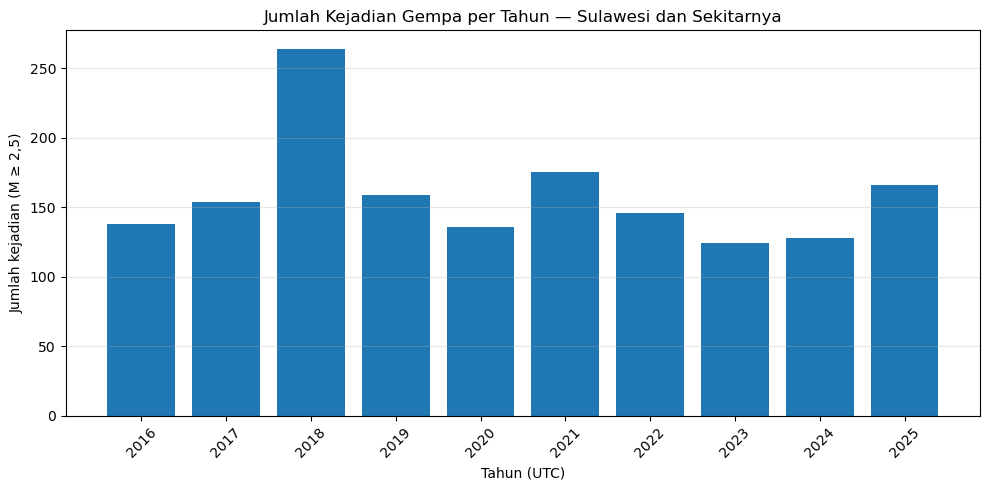

In [7]:
df_clean["year"] = df_clean["time"].dt.year
annual_counts = df_clean.groupby("year").size().rename("jumlah_gempa").reset_index()
display(annual_counts)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(annual_counts["year"].astype(str), annual_counts["jumlah_gempa"])
ax.set_title("Jumlah Kejadian Gempa per Tahun — Sulawesi dan Sekitarnya")
ax.set_xlabel("Tahun (UTC)")
ax.set_ylabel("Jumlah kejadian (M ≥ 2,5)")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. Distribusi magnitudo dan kedalaman

Histogram membantu melihat sebaran nilai dalam katalog. Bentuk distribusi ini tidak dengan sendirinya menunjukkan bahaya seismik atau probabilitas kejadian masa depan.

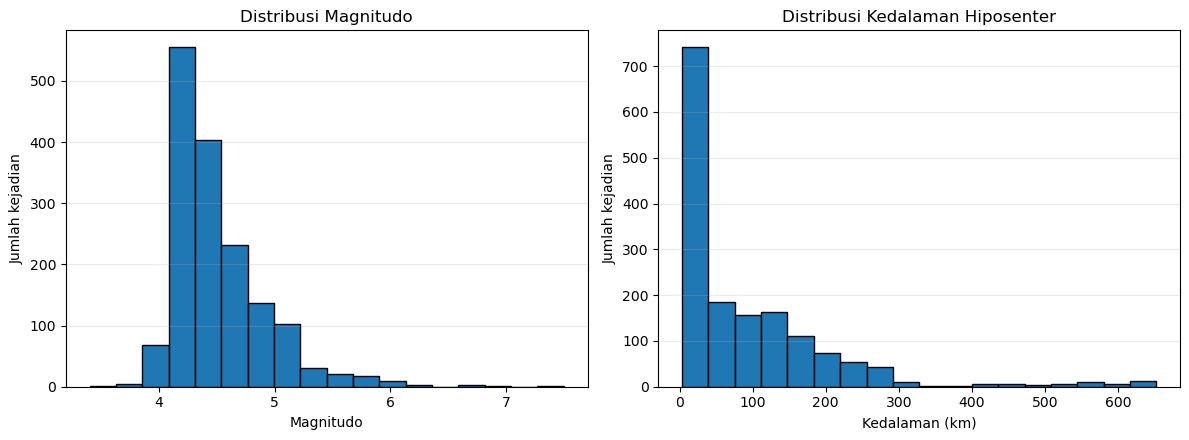

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(df_clean["mag"].dropna(), bins=18, edgecolor="black")
axes[0].set_title("Distribusi Magnitudo")
axes[0].set_xlabel("Magnitudo")
axes[0].set_ylabel("Jumlah kejadian")

axes[1].hist(df_clean["depth"].dropna(), bins=18, edgecolor="black")
axes[1].set_title("Distribusi Kedalaman Hiposenter")
axes[1].set_xlabel("Kedalaman (km)")
axes[1].set_ylabel("Jumlah kejadian")

for ax in axes:
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

## 7. Peta sebaran episenter sederhana

Peta ini menggunakan koordinat geografis (longitude/latitude) dan bukan proyeksi peta. Ukuran simbol dibedakan berdasarkan magnitudo untuk membantu visualisasi, tetapi ukuran simbol bukan ukuran fisik patahan atau luas dampak.

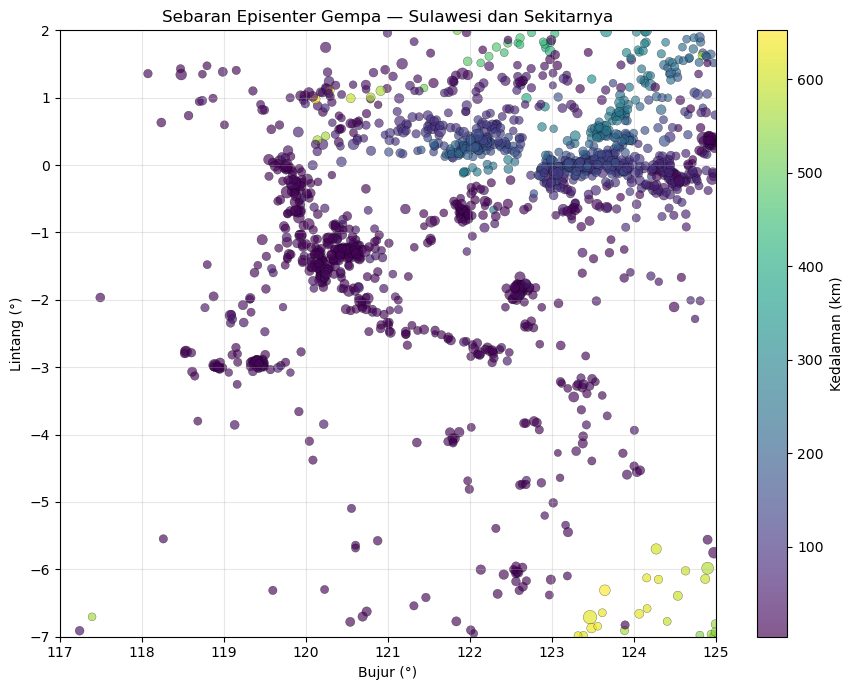

In [9]:
fig, ax = plt.subplots(figsize=(9, 7))
sizes = np.clip((df_clean["mag"].fillna(2.5) ** 2) * 2, 8, 220)
sc = ax.scatter(
    df_clean["longitude"], df_clean["latitude"],
    c=df_clean["depth"], s=sizes, alpha=0.65,
    edgecolors="black", linewidths=0.25
)
cb = plt.colorbar(sc, ax=ax)
cb.set_label("Kedalaman (km)")
ax.set_xlim(PARAMS["minlongitude"], PARAMS["maxlongitude"])
ax.set_ylim(PARAMS["minlatitude"], PARAMS["maxlatitude"])
ax.set_xlabel("Bujur (°)")
ax.set_ylabel("Lintang (°)")
ax.set_title("Sebaran Episenter Gempa — Sulawesi dan Sekitarnya")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Simpan hasil olahan

Notebook menyimpan CSV mentah, CSV hasil QA/QC, dan tabel frekuensi tahunan. Simpan pula notebook yang sudah dijalankan agar parameter dan hasil dapat ditelusuri.

In [10]:
clean_path = OUT_DIR / "katalog_gempa_usgs_sulawesi_bersih.csv"
annual_path = OUT_DIR / "jumlah_gempa_per_tahun.csv"
qc_path = OUT_DIR / "laporan_qc.csv"

df_clean.to_csv(clean_path, index=False)
annual_counts.to_csv(annual_path, index=False)
pd.Series(qc_report, name="nilai").to_csv(qc_path, header=True)

print("Hasil tersimpan:")
print("-", raw_path)
print("-", clean_path)
print("-", annual_path)
print("-", qc_path)

Hasil tersimpan:
- hasil_recipe_katalog_gempa\katalog_gempa_usgs_sulawesi_raw.csv
- hasil_recipe_katalog_gempa\katalog_gempa_usgs_sulawesi_bersih.csv
- hasil_recipe_katalog_gempa\jumlah_gempa_per_tahun.csv
- hasil_recipe_katalog_gempa\laporan_qc.csv


## 9. Optional check — verifikasi akhir

Pemeriksaan ini memastikan tabel hasil tidak kosong dan koordinat tetap berada dalam batas pencarian. Ini adalah pemeriksaan konsistensi sederhana, bukan validasi seismologis independen.

In [11]:
assert not df_clean.empty, "Tabel bersih kosong"
assert df_clean["latitude"].between(PARAMS["minlatitude"], PARAMS["maxlatitude"]).all()
assert df_clean["longitude"].between(PARAMS["minlongitude"], PARAMS["maxlongitude"]).all()
assert (df_clean["depth"] >= 0).all()
assert df_clean["mag"].notna().all()
assert df_clean["time"].notna().all()

if "id" in df_clean.columns:
    assert not df_clean["id"].duplicated().any()

print("Pemeriksaan konsistensi dasar: LULUS")
print("Ingat: hasil statistik berlaku untuk parameter dan versi katalog yang digunakan.")

Pemeriksaan konsistensi dasar: LULUS
Ingat: hasil statistik berlaku untuk parameter dan versi katalog yang digunakan.
